# Sparse recovery: ISTA, FISTA, OMP, and beating Nyquist

A sensor gives us far fewer measurements than the signal has unknowns. Such a
system has infinitely many solutions, so we need a rule to pick one. Compressed
sensing picks the *sparsest* one, and this notebook builds the three standard
solvers that do it. We then use them to rebuild a signal sampled more than five
times below its Nyquist rate, with essentially zero error.

**In this notebook you will**

* write ISTA, FISTA and OMP from scratch in a few lines each, and check them
  against `sklearn`;
* measure how many iterations ISTA and FISTA need, and compare with the
  worst-case theory;
* see why LASSO amplitudes are too small and fix them with a debiasing step;
* recover a two-tone signal from 128 random samples where Nyquist asks for 674.

**Before this notebook:** `cs_phase_transition` (when does $\ell_1$ recovery
succeed?). **Next:** `cs_uniform_vs_random` (uniform versus random sampling
with the same sample budget).

**Runtime:** about 15 seconds on a laptop (most of it is the long reference run
of 40,000 FISTA iterations and the 20,000-iteration comparison).

## The problem

We measure $\boldsymbol{y}=\boldsymbol{\Phi}\boldsymbol{s}\in\mathbb{R}^m$, where
$\boldsymbol{s}\in\mathbb{R}^n$ is the unknown coefficient vector and
$\boldsymbol{\Phi}\in\mathbb{R}^{m\times n}$ is the sensing matrix, with $m\ll n$.
The system is underdetermined, so we ask for the sparsest explanation. Counting
nonzeros (the $\ell_0$ problem) is NP-hard. Its convex relaxation is the LASSO

$$\min_{\boldsymbol{s}}\ F(\boldsymbol{s})=\underbrace{\tfrac12\|\boldsymbol{y}-\boldsymbol{\Phi}\boldsymbol{s}\|_2^2}_{f(\boldsymbol{s})}
  +\underbrace{\lambda\|\boldsymbol{s}\|_1}_{g(\boldsymbol{s})} .$$

Here $\lambda>0$ trades data fit against sparsity. The objective splits into a
smooth part $f$ (a quadratic) and a non-smooth part $g$ (the $\ell_1$ norm). That
split is exactly what proximal gradient methods exploit:

* **ISTA:** take a gradient step on $f$, then soft-threshold. Worst-case rate $O(1/k)$.
* **FISTA:** the same step, but taken from an extrapolated (momentum) point.
  Worst-case rate $O(1/k^2)$ (Beck and Teboulle, 2009).
* **OMP:** greedy. Add the column most correlated with the residual, re-fit, repeat.

Both proximal methods are written from scratch, cross-checked against `sklearn`,
and then used for the central claim of compressed sensing: exact recovery of a
signal sampled **far below** its Nyquist rate.

**Where the settings live.** This notebook has no single parameter cell. The
random seed is in the setup cell below (`default_rng(2)`). The test problem
($n$, $k$, $m$, $\lambda$) is set at the top of Section 2, the iteration budget
and tolerance at the top of Section 3, and the two-tone signal and sample count
at the top of Section 5.

**Setup.** Imports, the course plot style, the output folder for figures, and
one random generator with a fixed seed so that every run gives the same numbers.

In [1]:
import sys, os, time
sys.path.insert(0, os.path.abspath(os.path.join('..', '..')))
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import idct, dct
from pyutils import set_plot_style, save_dual, fg, muted
set_plot_style()

FIG = os.path.abspath(os.path.join('..', 'figures')); os.makedirs(FIG, exist_ok=True)
rng = np.random.default_rng(2)   # one generator for the whole notebook

## 1. The solvers, from scratch

### Two building blocks

**Soft thresholding** is the proximal operator of $a\|\cdot\|_1$. It acts on each
entry separately:

$$\big[S_a(\boldsymbol{z})\big]_j=\operatorname{sign}(z_j)\,\max(|z_j|-a,\,0).$$

In words: entries smaller than $a$ in magnitude are set to zero, and every other
entry is pulled towards zero by exactly $a$. This is where sparsity comes from,
and also where the downward bias of LASSO amplitudes comes from (Section 4).

`lasso_objective` evaluates $F(\boldsymbol{s})$ so that we can track convergence.

In [2]:
def soft_threshold(z, a):
    """prox of a*||.||_1 : sign(z) * max(|z| - a, 0)."""
    return np.sign(z)*np.maximum(np.abs(z) - a, 0.0)


def lasso_objective(Phi, y, s, lam):
    r = y - Phi @ s
    return 0.5*r @ r + lam*np.sum(np.abs(s))

### ISTA (iterative shrinkage-thresholding algorithm)

Start from $\boldsymbol{s}_0=\boldsymbol{0}$ and repeat

$$\boldsymbol{s}_{k+1}=S_{\lambda/L}\!\Big(\boldsymbol{s}_k-\tfrac{1}{L}\,\boldsymbol{\Phi}^\top(\boldsymbol{\Phi}\boldsymbol{s}_k-\boldsymbol{y})\Big).$$

Step by step:

1. $\boldsymbol{\Phi}\boldsymbol{s}_k-\boldsymbol{y}$ is the current residual,
   and $\boldsymbol{\Phi}^\top(\boldsymbol{\Phi}\boldsymbol{s}_k-\boldsymbol{y})$ is
   the gradient $\nabla f(\boldsymbol{s}_k)$ of the smooth part.
2. Take a gradient step of length $1/L$. Here $L=\|\boldsymbol{\Phi}\|_2^2$ (the
   largest singular value of $\boldsymbol{\Phi}$, squared) is the Lipschitz
   constant of $\nabla f$. A step of $1/L$ is the largest step that is
   guaranteed never to increase $f$.
3. Soft-threshold the result with threshold $\lambda/L$. This handles the
   non-smooth part $g$ exactly.

The optional `track` argument lets us record any quantity per iteration instead
of the objective (we use it later to watch the support).

In [3]:
def ista(Phi, y, lam, n_iter, L=None, track=None):
    """Iterative shrinkage-thresholding. Returns (s, objective history)."""
    n = Phi.shape[1]
    L = L if L is not None else np.linalg.norm(Phi, 2)**2   # ||Phi||_2^2 = Lipschitz const. of grad f
    s = np.zeros(n)
    hist = np.empty(n_iter)
    for k in range(n_iter):
        # gradient step on f, then shrink: one line is the whole algorithm
        s = soft_threshold(s - (Phi.T @ (Phi @ s - y))/L, lam/L)
        hist[k] = lasso_objective(Phi, y, s, lam) if track is None else track(s)
    return s, hist

### FISTA (fast ISTA)

FISTA does the same gradient-plus-shrink step, but from an extrapolated point
$\boldsymbol{z}_k$ instead of from $\boldsymbol{s}_k$. Start from
$\boldsymbol{s}_0=\boldsymbol{z}_0=\boldsymbol{0}$, $t_0=1$, and repeat

$$\boldsymbol{s}_{k+1}=S_{\lambda/L}\!\Big(\boldsymbol{z}_k-\tfrac{1}{L}\,\boldsymbol{\Phi}^\top(\boldsymbol{\Phi}\boldsymbol{z}_k-\boldsymbol{y})\Big),\qquad
  t_{k+1}=\tfrac12\Big(1+\sqrt{1+4t_k^2}\Big),\qquad
  \boldsymbol{z}_{k+1}=\boldsymbol{s}_{k+1}+\frac{t_k-1}{t_{k+1}}\big(\boldsymbol{s}_{k+1}-\boldsymbol{s}_k\big).$$

Step by step:

1. The ISTA step, evaluated at $\boldsymbol{z}_k$, gives the new iterate
   $\boldsymbol{s}_{k+1}$.
2. The scalar $t_k$ grows roughly like $k/2$. The weight
   $(t_k-1)/t_{k+1}$ therefore starts at $0$ and creeps towards $1$.
3. $\boldsymbol{z}_{k+1}$ continues along the last direction of travel
   $\boldsymbol{s}_{k+1}-\boldsymbol{s}_k$, like a heavy ball rolling downhill.
   This momentum is the only difference from ISTA, and it costs nothing extra:
   one matrix-vector product with $\boldsymbol{\Phi}$ and one with
   $\boldsymbol{\Phi}^\top$ per iteration, exactly as in ISTA.

In [4]:
def fista(Phi, y, lam, n_iter, L=None, track=None):
    """Beck & Teboulle (2009): ISTA + Nesterov momentum. Returns (s, history)."""
    n = Phi.shape[1]
    L = L if L is not None else np.linalg.norm(Phi, 2)**2
    s = np.zeros(n); z = s.copy(); t = 1.0
    hist = np.empty(n_iter)
    for k in range(n_iter):
        s_new = soft_threshold(z - (Phi.T @ (Phi @ z - y))/L, lam/L)   # ISTA step taken from z
        t_new = 0.5*(1.0 + np.sqrt(1.0 + 4.0*t*t))                      # momentum schedule
        z = s_new + ((t - 1.0)/t_new)*(s_new - s)                       # extrapolate along last move
        s, t = s_new, t_new
        hist[k] = lasso_objective(Phi, y, s, lam) if track is None else track(s)
    return s, hist

### OMP (orthogonal matching pursuit)

OMP does not minimise the LASSO at all. It builds the support one index at a time.
Let $\boldsymbol{r}$ be the residual (initially $\boldsymbol{r}=\boldsymbol{y}$),
$\Lambda$ the set of chosen indices (initially empty), $\boldsymbol{\phi}_j$ the
$j$-th column of $\boldsymbol{\Phi}$, and $\boldsymbol{\Phi}_\Lambda$ the columns
indexed by $\Lambda$. Repeat $k$ times:

1. **Select:** $j=\arg\max_j |\boldsymbol{\phi}_j^\top\boldsymbol{r}|$, the column
   that best explains what is still unexplained.
2. **Add:** $\Lambda\leftarrow\Lambda\cup\{j\}$. (If $j$ is already in $\Lambda$,
   nothing new can be learned and we stop.)
3. **Re-fit:** solve the small least-squares problem
   $\min_{\boldsymbol{c}}\|\boldsymbol{y}-\boldsymbol{\Phi}_\Lambda\boldsymbol{c}\|_2$
   on the chosen columns.
4. **Update:** $\boldsymbol{r}=\boldsymbol{y}-\boldsymbol{\Phi}_\Lambda\boldsymbol{c}$.
   Because of the re-fit, $\boldsymbol{r}$ is orthogonal to every chosen column
   (hence "orthogonal" in the name), so no column is ever picked twice in exact
   arithmetic.

OMP needs the sparsity $k$ as an input. ISTA and FISTA need $\lambda$ instead.

In [5]:
def omp(Phi, y, k):
    """Orthogonal matching pursuit: k greedy column selections."""
    r, idx = y.copy(), []
    for _ in range(k):
        j = int(np.argmax(np.abs(Phi.T @ r)))          # most correlated column
        if j in idx:
            break
        idx.append(j)
        coef, *_ = np.linalg.lstsq(Phi[:, idx], y, rcond=None)   # re-fit on all chosen columns
        r = y - Phi[:, idx] @ coef
    s = np.zeros(Phi.shape[1]); s[idx] = coef
    return s, sorted(idx)

## 2. A canonical sparse-recovery problem

We build a test case where we know the answer:

* $n=1024$ unknowns, of which $k=20$ are nonzero. The support (the positions of
  the nonzeros) is random; each nonzero has a random sign and a magnitude
  between 1 and 3.
* $m=256$ measurements through a Gaussian matrix $\boldsymbol{\Phi}$ with
  entries of variance $1/m$ (so its columns have roughly unit length).
  That is a compression factor of $4\times$ against the ambient dimension and
  $12.8$ measurements per nonzero.
* $\lambda$ is set to $1\%$ of $\|\boldsymbol{\Phi}^\top\boldsymbol{y}\|_\infty$.
  For $\lambda\ge\|\boldsymbol{\Phi}^\top\boldsymbol{y}\|_\infty$ the LASSO
  solution is exactly $\boldsymbol{0}$, so $1\%$ of that value is a light penalty.

We also need the true optimal value $F^*=F(\boldsymbol{s}^*)$ to measure
convergence. We get it by running FISTA for 40,000 iterations, far longer than
needed, and call that solution the reference $\boldsymbol{s}_{\mathrm{ref}}$.

In [6]:
N, K, M = 1024, 20, 256
support = np.sort(rng.choice(N, K, replace=False))
s_true = np.zeros(N)
s_true[support] = rng.choice([-1, 1], K)*rng.uniform(1.0, 3.0, K)   # random sign, magnitude in [1, 3]

Phi = rng.standard_normal((M, N))/np.sqrt(M)
y = Phi @ s_true
L = np.linalg.norm(Phi, 2)**2
LAM = 0.01*np.max(np.abs(Phi.T @ y))         # 1% of the value that would zero out every coefficient
print(f"n={N}, k={K}, m={M}  ->  m/n = {M/N:.2f}, m/k = {M/K:.1f}")
print(f"Lipschitz constant L = {L:.3f},  lambda = {LAM:.4f}")

# high-accuracy reference solution and its optimal value F*
s_ref, _ = fista(Phi, y, LAM, 40_000, L=L)
F_STAR = lasso_objective(Phi, y, s_ref, LAM)
print(f"reference LASSO optimum F* = {F_STAR:.10f}")

n=1024, k=20, m=256  ->  m/n = 0.25, m/k = 12.8
Lipschitz constant L = 8.792,  lambda = 0.0292


reference LASSO optimum F* = 1.2040643748


The problem keeps a quarter of the dimensions ($m/n=0.25$) and $12.8$
measurements per nonzero. The Lipschitz constant is $L=8.792$, so ISTA and FISTA
take steps of length $1/L$. The penalty is $\lambda=0.0292$, and the reference
optimum is $F^*=1.2040643748$.

### Cross-check against `sklearn`

Before trusting our solvers we compare with an independent implementation.
`sklearn`'s `Lasso` minimises
$\frac{1}{2m}\|\boldsymbol{y}-\boldsymbol{\Phi}\boldsymbol{s}\|_2^2+\alpha\|\boldsymbol{s}\|_1$,
which is our objective divided by $m$. So the same problem uses $\alpha=\lambda/m$.
`sklearn` uses coordinate descent, a completely different algorithm, so agreement
is a strong check.

In [7]:
from sklearn.linear_model import Lasso
sk = Lasso(alpha=LAM/M, fit_intercept=False, max_iter=200_000, tol=1e-14).fit(Phi, y)
F_sk = lasso_objective(Phi, y, sk.coef_, LAM)
print(f"our FISTA F = {F_STAR:.10f}   sklearn F = {F_sk:.10f}   "
      f"||s_ours - s_sklearn||/||s|| = {np.linalg.norm(s_ref-sk.coef_)/np.linalg.norm(s_ref):.2e}")
assert abs(F_STAR - F_sk)/F_sk < 1e-6, "our solver must agree with sklearn on the optimum"

our FISTA F = 1.2040643748   sklearn F = 1.2040643748   ||s_ours - s_sklearn||/||s|| = 9.56e-16


Both solvers reach $F=1.2040643748$ to all ten printed digits, and the two
solution vectors differ by $9.56\times10^{-16}$ relative to their size, which is
machine precision. Our FISTA solves the right problem.

## 3. ISTA vs FISTA: iterations to a fixed accuracy

Now we run both methods for `NIT` $=20{,}000$ iterations from
$\boldsymbol{s}_0=\boldsymbol{0}$ and record the **relative objective gap**

$$\frac{F(\boldsymbol{s}_k)-F^*}{F^*}$$

after every iteration. `iters_to` returns the first iteration at which the gap
drops below a tolerance (`TOL` $=10^{-6}$ is the headline one). The gap is floored
at $10^{-16}$ so that we can take logarithms later. We also time both runs: the
cost per iteration should be the same.

In [8]:
NIT = 20_000
TOL = 1e-6                        # relative objective gap

t0 = time.perf_counter(); s_i, hist_i = ista(Phi, y, LAM, NIT, L=L); t_ista = time.perf_counter()-t0
t0 = time.perf_counter(); s_f, hist_f = fista(Phi, y, LAM, NIT, L=L); t_fista = time.perf_counter()-t0

gap_i = np.maximum(hist_i - F_STAR, 1e-16)/F_STAR    # floor avoids log(0) and tiny negative round-off
gap_f = np.maximum(hist_f - F_STAR, 1e-16)/F_STAR


def iters_to(gap, tol):
    hit = np.flatnonzero(gap <= tol)
    return int(hit[0]) + 1 if hit.size else np.inf    # +1: iteration count, not 0-based index


it_i, it_f = iters_to(gap_i, TOL), iters_to(gap_f, TOL)
speedup = it_i/it_f
print(f"iterations to relative objective gap {TOL:.0e}:  ISTA {it_i},  FISTA {it_f}  "
      f"-> x{speedup:.1f} fewer")
print(f"wall clock for {NIT} iterations: ISTA {t_ista:.2f} s, FISTA {t_fista:.2f} s "
      f"(same cost per iteration)")
for tol in (1e-3, 1e-4, 1e-6, 1e-8):
    print(f"   tol {tol:.0e}: ISTA {iters_to(gap_i, tol):>6}   FISTA {iters_to(gap_f, tol):>6}"
          f"   ratio {iters_to(gap_i, tol)/iters_to(gap_f, tol):.1f}")

assert speedup >= 3.0, "FISTA must be materially faster than ISTA"

iterations to relative objective gap 1e-06:  ISTA 619,  FISTA 158  -> x3.9 fewer
wall clock for 20000 iterations: ISTA 2.18 s, FISTA 2.22 s (same cost per iteration)
   tol 1e-03: ISTA    562   FISTA     92   ratio 6.1
   tol 1e-04: ISTA    582   FISTA    118   ratio 4.9
   tol 1e-06: ISTA    619   FISTA    158   ratio 3.9
   tol 1e-08: ISTA    657   FISTA    211   ratio 3.1


To reach a gap of $10^{-6}$, ISTA needs 619 iterations and FISTA needs 158, a
factor of 3.9. The two wall-clock times are almost equal, so fewer iterations
means proportionally less time. The table shows the ratio is largest for loose
tolerances (6.1 at $10^{-3}$) and shrinks for tight ones (3.1 at $10^{-8}$).
Note also how close together ISTA's counts are (562 to 657): once ISTA starts to
converge, it converges very fast. The next cell explains why.

### Theory check: the worst-case bounds

The $O(1/k)$ and $O(1/k^2)$ rates are worst-case **upper bounds**. With
$\boldsymbol{s}^*$ the minimiser and $\boldsymbol{s}_0$ the starting point:

$$F(\boldsymbol{s}_k)-F^*\le \frac{L\|\boldsymbol{s}_0-\boldsymbol{s}^*\|_2^2}{2k}\quad\text{(ISTA)},\qquad
  F(\boldsymbol{s}_k)-F^*\le \frac{2L\|\boldsymbol{s}_0-\boldsymbol{s}^*\|_2^2}{(k+1)^2}\quad\text{(FISTA)}.$$

We start from $\boldsymbol{s}_0=\boldsymbol{0}$, so
$\|\boldsymbol{s}_0-\boldsymbol{s}^*\|_2=\|\boldsymbol{s}_{\mathrm{ref}}\|_2$
(called `R0` in the code). Both bounds are divided by $F^*$ to match our relative
gap. The cell prints the largest ratio of actual gap to bound over all
iterations: theory says it can never exceed 1.

In [9]:
kk = np.arange(1, NIT+1)
R0 = np.linalg.norm(s_ref)                       # ||s_0 - s*||, with s_0 = 0
bound_ista = L*R0**2/(2*kk)/F_STAR
bound_fista = 2*L*R0**2/(kk + 1.0)**2/F_STAR
print(f"worst ratio actual/bound: ISTA {np.max(gap_i/bound_ista):.3f}, "
      f"FISTA {np.max(gap_f/bound_fista):.3f}   (theory says <= 1)")
assert np.max(gap_i/bound_ista) <= 1.0, "ISTA must respect its O(1/k) bound"
assert np.max(gap_f/bound_fista) <= 1.0, "FISTA must respect its O(1/k^2) bound"

worst ratio actual/bound: ISTA 0.288, FISTA 0.522   (theory says <= 1)


Both methods respect their bounds: the worst ratio is 0.288 for ISTA and 0.522
for FISTA. Over most iterations the actual gap is far below the bound, which
the figure further down makes visible.

### What actually happens: the support settles, then convergence is linear

Why do both methods beat their worst-case rates by so much? Soft thresholding
sets most entries to exactly zero. After some iteration the set of nonzero
entries stops changing. From then on the LASSO restricted to that support is a
smooth, strongly convex least-squares problem, and gradient methods on such
problems converge **linearly**: the gap shrinks by a constant factor $\rho<1$
every iteration, $\text{gap}_{k+1}\approx\rho\,\text{gap}_k$.

The cell measures this in two steps:

1. `support_flag` returns 1 when the nonzero pattern of the iterate equals the
   true support exactly, and `settle_iter` finds the first iteration after which
   the flag stays at 1. We run both methods for 2000 iterations with this
   tracker.
2. A straight-line fit of $\log(\text{gap})$ against $k$ just after settling
   (200 iterations for ISTA, 120 for FISTA) gives the slope $\log\rho$; we print
   $\rho$.

In [10]:
def support_flag(s):
    return float(np.array_equal(np.flatnonzero(np.abs(s) > 0), support))


def settle_iter(hist):
    bad = np.flatnonzero(hist == 0.0)                 # iterations where the support was wrong
    return int(bad[-1]) + 2 if bad.size else 1        # first 1-based iteration after the last wrong one


_, hi_s = ista(Phi, y, LAM, 2000, L=L, track=support_flag)
_, hf_s = fista(Phi, y, LAM, 2000, L=L, track=support_flag)
k_supp_i, k_supp_f = settle_iter(hi_s), settle_iter(hf_s)
print(f"iteration at which the true support is identified and held: "
      f"ISTA {k_supp_i}, FISTA {k_supp_f}")
# once the support is fixed the LASSO is a smooth strongly convex problem on
# that support, so both methods switch to LINEAR convergence -- far faster than
# the sublinear worst case. Measure the post-settling decay factor per iteration.
tail_i = np.polyfit(kk[k_supp_i:k_supp_i+200], np.log(gap_i[k_supp_i:k_supp_i+200]), 1)[0]
tail_f = np.polyfit(kk[k_supp_f:k_supp_f+120], np.log(gap_f[k_supp_f:k_supp_f+120]), 1)[0]
print(f"post-settling linear rate (gap shrinks by this factor per iteration): "
      f"ISTA {np.exp(tail_i):.4f}, FISTA {np.exp(tail_f):.4f}")
print(f"-> the win is WHEN the support is found: FISTA gets there "
      f"x{k_supp_i/k_supp_f:.1f} sooner; the local rates afterwards are comparable")
assert tail_i < 0 and tail_f < 0, "both must converge linearly once the support settles"
assert k_supp_f < k_supp_i/3, "FISTA must identify the support far earlier than ISTA"

iteration at which the true support is identified and held: ISTA 620, FISTA 118
post-settling linear rate (gap shrinks by this factor per iteration): ISTA 0.8921, FISTA 0.9253
-> the win is WHEN the support is found: FISTA gets there x5.3 sooner; the local rates afterwards are comparable


ISTA locks onto the true support at iteration 620 and FISTA at iteration 118,
which is 5.3 times sooner. After that the per-iteration factors are 0.8921 (ISTA)
and 0.9253 (FISTA): both are linear, and ISTA's is in fact slightly faster.
So momentum does not make the final phase faster here. Its whole benefit is
reaching the correct support earlier. Compare 620 with the 619 iterations ISTA
needed for a $10^{-6}$ gap: ISTA reaches that accuracy right as its support
settles.

## 4. Did we get the right answer? Support recovery and debiasing

The first check is the support: we call an entry of $\boldsymbol{s}_{\mathrm{ref}}$
nonzero if it exceeds $10^{-3}$ of the largest entry, and compare that set with
the true support.

The $\ell_1$ penalty shrinks every surviving coefficient towards zero (by
$\lambda/L$ per soft-threshold step, balanced at the optimum by the data term),
so LASSO amplitudes are biased low. The standard cure is **debiasing**: keep the
support $\hat\Lambda$ that LASSO found, and solve an ordinary least-squares
problem on it,

$$\hat{\boldsymbol{s}}_{\hat\Lambda}=\arg\min_{\boldsymbol{c}}\|\boldsymbol{y}-\boldsymbol{\Phi}_{\hat\Lambda}\boldsymbol{c}\|_2,\qquad \hat{\boldsymbol{s}}_j=0\ \text{for } j\notin\hat\Lambda .$$

With 256 equations and 20 unknowns this is well posed and has no penalty, so no
shrinkage. Errors are relative to the true vector,
$\|\hat{\boldsymbol{s}}-\boldsymbol{s}_{\mathrm{true}}\|_2/\|\boldsymbol{s}_{\mathrm{true}}\|_2$.

In [11]:
supp_hat = np.flatnonzero(np.abs(s_ref) > 1e-3*np.max(np.abs(s_ref)))
exact_support = np.array_equal(supp_hat, support)
print(f"true support size {K}, recovered {supp_hat.size}, exact match: {exact_support}")
assert exact_support, "LASSO must recover the exact support at this sampling rate"

s_deb = np.zeros(N)
s_deb[supp_hat] = np.linalg.lstsq(Phi[:, supp_hat], y, rcond=None)[0]   # least squares on the support only
err_lasso = np.linalg.norm(s_ref - s_true)/np.linalg.norm(s_true)
err_deb = np.linalg.norm(s_deb - s_true)/np.linalg.norm(s_true)
print(f"relative error: LASSO {err_lasso:.3e}   debiased {err_deb:.3e}  "
      f"-> shrinkage bias removed, x{err_lasso/err_deb:.0e}")
assert err_lasso < 5e-2 and err_deb < 1e-10

true support size 20, recovered 20, exact match: True
relative error: LASSO 1.719e-02   debiased 1.302e-15  -> shrinkage bias removed, x1e+13


LASSO finds all 20 nonzeros and no false ones. Its amplitudes are off by
$1.719\times10^{-2}$ (about 1.7%), which is the shrinkage bias. After debiasing
the error is $1.302\times10^{-15}$, machine precision: a factor of about
$10^{13}$ better. LASSO's job is to find *where* the nonzeros are; least squares
then finds *how big* they are.

### OMP on the same problem

Now the greedy alternative: 20 OMP steps (we tell it $k=20$), timed. OMP ends
with a least-squares fit on its support, so it has no shrinkage bias.

In [12]:
t0 = time.perf_counter(); s_omp, idx_omp = omp(Phi, y, K); t_omp = time.perf_counter()-t0
err_omp = np.linalg.norm(s_omp - s_true)/np.linalg.norm(s_true)
print(f"OMP ({K} greedy steps, {t_omp*1e3:.1f} ms): support exact "
      f"{np.array_equal(np.array(idx_omp), support)}, rel. error {err_omp:.2e}")
assert np.array_equal(np.array(idx_omp), support)

OMP (20 greedy steps, 1.8 ms): support exact True, rel. error 1.27e-15


OMP picks the exact support in 20 steps and reaches a relative error of
$1.27\times10^{-15}$, in milliseconds (the printed time) rather than the seconds
spent on thousands of FISTA iterations. On an easy, well-separated problem like
this one, greed is cheap and exact. OMP is also the first method to fail as the
problem gets harder (more nonzeros, fewer measurements), because one wrong early
pick can never be undone.

### Figure: recovered coefficients and convergence histories

The next cell draws two panels: the recovered vector against the truth, and the
relative objective gap of ISTA and FISTA against their worst-case bounds. It
saves a light and a dark version of the figure as `cs_recovery`.

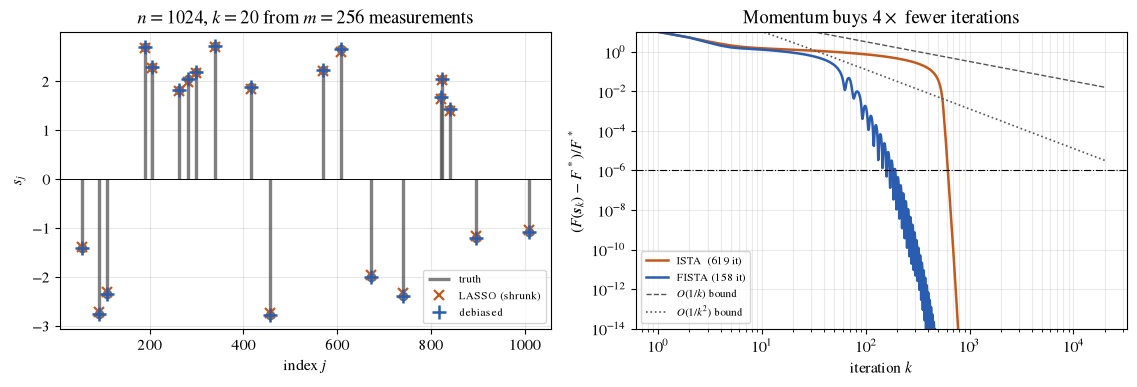

In [13]:
def plot_recovery():
    fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.0))
    ax[0].vlines(support, 0, s_true[support], color=muted(), lw=2.4, alpha=0.75,
                 label='truth')
    ax[0].plot(support, s_true[support], 'o', color=muted(), ms=6, alpha=0.75)
    ax[0].plot(np.flatnonzero(s_ref), s_ref[np.flatnonzero(s_ref)], 'x', color='C1',
               ms=7, mew=1.6, label='LASSO (shrunk)')
    ax[0].plot(supp_hat, s_deb[supp_hat], '+', color='C0', ms=10, mew=1.8,
               label='debiased')
    ax[0].axhline(0, color=fg(), lw=0.7)
    ax[0].set(xlabel='index $j$', ylabel='$s_j$',
              title=f'$n={N}$, $k={K}$ from $m={M}$ measurements')
    ax[0].legend(fontsize=8, loc='lower right')
    ax[1].loglog(kk, gap_i, color='C1', lw=1.8, label=f'ISTA  ({it_i} it)')
    ax[1].loglog(kk, gap_f, color='C0', lw=1.8, label=f'FISTA ({it_f} it)')
    ax[1].loglog(kk, bound_ista, ls='--', color=muted(), lw=1.0,
                 label='$O(1/k)$ bound')
    ax[1].loglog(kk, bound_fista, ls=':', color=muted(), lw=1.2,
                 label='$O(1/k^2)$ bound')
    ax[1].axhline(TOL, color=fg(), lw=0.8, ls='-.')
    ax[1].set(xlabel='iteration $k$', ylabel='$(F(\\boldsymbol{s}_k)-F^*)/F^*$',
              title=f'Momentum buys ${speedup:.0f}\\times$ fewer iterations',
              ylim=(1e-14, 10))
    ax[1].legend(fontsize=8)
    ax[1].grid(True, which='both', alpha=0.25)
    plt.tight_layout()


save_dual(plot_recovery, 'cs_recovery', FIG)
plt.show()

**How to read this figure.** *Left panel:* the horizontal axis is the
coefficient index $j$ (0 to 1023) and the vertical axis is the value $s_j$.
Grey stems with dots are the 20 true nonzeros. Orange crosses are the LASSO
solution and blue plus signs are the debiased solution; all other indices are
zero and not drawn. *Right panel:* both axes are logarithmic. The horizontal axis
is the iteration $k$ and the vertical axis is the relative objective gap
$(F(\boldsymbol{s}_k)-F^*)/F^*$. Orange is ISTA and blue is FISTA (the legend
gives the iterations each needs to reach $10^{-6}$). The grey dashed line is the
$O(1/k)$ bound for ISTA, the grey dotted line is the $O(1/k^2)$ bound for FISTA,
and the black dash-dotted horizontal line marks the tolerance $10^{-6}$.

**What it shows.** *Left:* every orange cross and blue plus sits on a grey stem,
so the support is exactly right (20 of 20). The orange crosses sit slightly
closer to zero than the stem tips; that is the shrinkage (relative error
$1.719\times10^{-2}$). The blue plus signs sit exactly on the tips (error
$1.302\times10^{-15}$). *Right:* both curves stay well below their bound lines
(worst ratios 0.288 and 0.522). ISTA sits on a plateau and then drops almost
vertically around iteration 620, when its support settles. FISTA leaves the
plateau much earlier, wiggles (momentum makes FISTA non-monotone: it overshoots
and corrects), and crosses the $10^{-6}$ line at iteration 158 versus ISTA's 619.
The title's "$4\times$" is the rounded speed-up of 3.9. The takeaway: the
worst-case rates are a guarantee, not a prediction; the real speed comes from
how fast each method finds the support.

## 5. The headline: recovery below the Nyquist rate

The two-tone signal of `cs_sparsity`,
$x(t)=\cos(2\pi f_1 t)+\cos(2\pi f_2 t)$ with $f_1=97$ Hz and $f_2=337$ Hz,
lives on $n=1024$ grid points over $T=1$ s. Its highest frequency is
$f_{\max}=337$ Hz, so the Nyquist-Shannon theorem demands at least $674$ uniform
samples per second. We take only **128 random samples** (12.5% of the grid, a
rate $5.3\times$ *below* Nyquist) and reconstruct the full 1024-point signal.

The ingredients:

* $\boldsymbol{\Psi}\in\mathbb{R}^{n\times n}$ is the inverse DCT (discrete cosine
  transform) matrix, so $\boldsymbol{x}=\boldsymbol{\Psi}\boldsymbol{s}$ and
  $\boldsymbol{s}$ are the DCT coefficients. With this grid, DCT index $k$
  corresponds to frequency $k/(2T)$ Hz, so the two tones occupy exactly indices
  194 and 674: $\boldsymbol{s}$ has only 2 nonzeros.
* $\mathbf{C}\in\mathbb{R}^{m\times n}$ keeps $m=128$ randomly chosen rows of
  the identity, so $\boldsymbol{y}=\mathbf{C}\boldsymbol{x}$ are the samples.
* The sensing matrix is $\boldsymbol{\Phi}=\mathbf{C}\boldsymbol{\Psi}$: the DCT
  basis restricted to the sampled rows. Point samples are maximally
  *incoherent* with cosines (a spike in time is spread over all frequencies),
  which is exactly the second condition compressed sensing needs, next to
  sparsity.

The recovery runs in three steps: FISTA for 3000 iterations with $\lambda$ at
$0.5\%$ of $\|\boldsymbol{\Phi}^\top\boldsymbol{y}\|_\infty$; keep every
coefficient above $1\%$ of the largest as the support; debias with least squares
on that support, exactly as in Section 4. Finally
$\hat{\boldsymbol{x}}=\boldsymbol{\Psi}\hat{\boldsymbol{s}}$.

In [14]:
N1D, T, F1, F2 = 1024, 1.0, 97.0, 337.0
t_grid = (np.arange(N1D) + 0.5)*T/N1D           # cell-centred times (matches the DCT-II grid)
x_full = np.cos(2*np.pi*F1*t_grid) + np.cos(2*np.pi*F2*t_grid)
s_full = dct(x_full, norm='ortho')

PSI = idct(np.eye(N1D), norm='ortho', axis=0)      # x = PSI @ s
assert np.allclose(PSI @ s_full, x_full, atol=1e-10)

M_CS = 128
perm = np.sort(rng.choice(N1D, M_CS, replace=False))   # random sample positions = rows kept by C
y_cs = x_full[perm]
Phi_cs = PSI[perm, :]                                  # Phi = C Psi

rate_cs = M_CS/T
nyq = 2*F2
print(f"Nyquist rate {nyq:.0f} samples/s; we use {rate_cs:.0f} samples/s "
      f"-> {nyq/rate_cs:.1f}x below Nyquist ({100*M_CS/N1D:.1f}% of the grid)")

lam_cs = 0.005*np.max(np.abs(Phi_cs.T @ y_cs))
s_cs, _ = fista(Phi_cs, y_cs, lam_cs, 3000)
supp_cs = np.flatnonzero(np.abs(s_cs) > 1e-2*np.max(np.abs(s_cs)))           # support from LASSO
s_cs_deb = np.zeros(N1D)
s_cs_deb[supp_cs] = np.linalg.lstsq(Phi_cs[:, supp_cs], y_cs, rcond=None)[0]  # debias on it
x_rec = PSI @ s_cs_deb

err_cs = np.linalg.norm(x_rec - x_full)/np.linalg.norm(x_full)
print(f"recovered support: {supp_cs.tolist()}  (true: {[int(2*F1*T), int(2*F2*T)]})")
print(f"full-signal relative reconstruction error: {err_cs:.3e}")
assert err_cs < 1e-2, "sub-Nyquist recovery must be essentially exact"
assert sorted(supp_cs.tolist()) == [int(2*F1*T), int(2*F2*T)]

Nyquist rate 674 samples/s; we use 128 samples/s -> 5.3x below Nyquist (12.5% of the grid)
recovered support: [194, 674]  (true: [194, 674])
full-signal relative reconstruction error: 9.978e-14


With 128 samples per second against a Nyquist rate of 674, FISTA finds exactly
the two DCT indices 194 and 674, and the full 1024-point signal is rebuilt with
relative error $9.978\times10^{-14}$, which is round-off level.

### The honest control: interpolate the same samples

Is the success due to the samples or to the method? We give the **same** 128
samples to linear interpolation (`np.interp`), which knows nothing about
sparsity, and compute its relative error on the full grid.

In [15]:
# the honest control: what naive interpolation of the same 128 samples gives
x_naive = np.interp(t_grid, t_grid[perm], y_cs)
err_naive = np.linalg.norm(x_naive - x_full)/np.linalg.norm(x_full)
print(f"linear interpolation of the SAME samples: rel. error {err_naive:.3f} "
      f"-> compressed sensing is x{err_naive/err_cs:.0e} better")
assert err_naive > 50*err_cs

linear interpolation of the SAME samples: rel. error 1.227 -> compressed sensing is x1e+13 better


Linear interpolation has relative error 1.227, larger than the signal itself:
it is worse than predicting zero everywhere. Compressed sensing is about
$10^{13}$ times better with identical data. The information was in the samples
all along; only a method that uses the sparsity prior can get it out.

### Figure: sub-Nyquist recovery

Three panels: the samples, the recovered spectrum, and the reconstruction in
time. Saved as `cs_nyquist`.

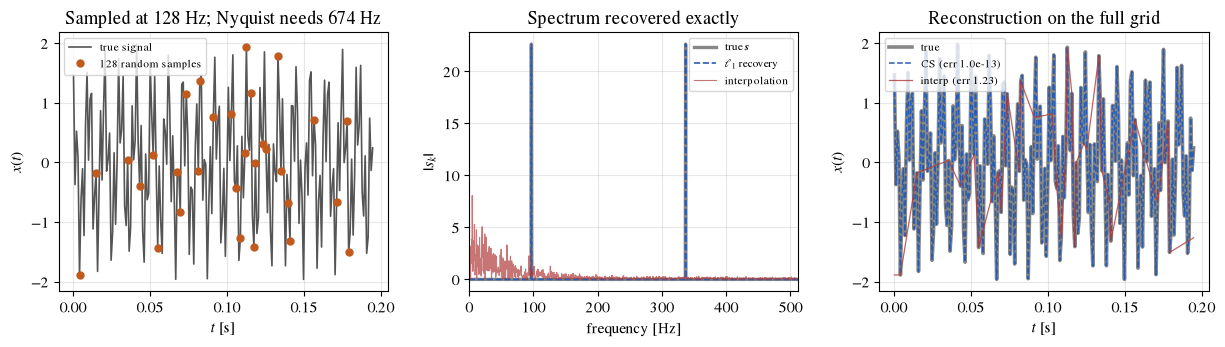

In [16]:
def plot_nyquist():
    fig, ax = plt.subplots(1, 3, figsize=(12.5, 3.6))
    win = slice(0, 200)                       # show only the first 200 grid points (about 0.2 s)
    ax[0].plot(t_grid[win], x_full[win], color=muted(), lw=1.2, label='true signal')
    pin = perm[perm < 200]                    # samples that fall inside that window
    ax[0].plot(t_grid[pin], x_full[pin], 'o', color='C1', ms=5,
               label=f'{M_CS} random samples')
    ax[0].set(xlabel='$t$ [s]', ylabel='$x(t)$',
              title=f'Sampled at {rate_cs:.0f} Hz; Nyquist needs {nyq:.0f} Hz')
    ax[0].legend(fontsize=8)
    f_ax = np.arange(N1D)/(2*T)               # DCT index k -> frequency k/(2T) Hz
    ax[1].plot(f_ax, np.abs(s_full), color=muted(), lw=2.4, alpha=0.7, label='true $\\boldsymbol{s}$')
    ax[1].plot(f_ax, np.abs(s_cs_deb), color='C0', lw=1.2, ls='--', label='$\\ell_1$ recovery')
    ax[1].plot(f_ax, np.abs(dct(x_naive, norm='ortho')), color='C3', lw=0.8, alpha=0.7,
               label='interpolation')
    ax[1].set(xlabel='frequency [Hz]', ylabel='$|s_k|$', xlim=(0, 512),
              title='Spectrum recovered exactly')
    ax[1].legend(fontsize=8)
    ax[2].plot(t_grid[win], x_full[win], color=muted(), lw=2.6, alpha=0.7, label='true')
    ax[2].plot(t_grid[win], x_rec[win], color='C0', lw=1.1, ls='--',
               label=f'CS (err {err_cs:.1e})')
    ax[2].plot(t_grid[win], x_naive[win], color='C3', lw=0.9, alpha=0.8,
               label=f'interp (err {err_naive:.2f})')
    ax[2].set(xlabel='$t$ [s]', ylabel='$x(t)$', title='Reconstruction on the full grid')
    ax[2].legend(fontsize=8)
    plt.tight_layout()


save_dual(plot_nyquist, 'cs_nyquist', FIG)
plt.show()

**How to read this figure.** *Left:* the first 200 grid points (about the first
0.2 s) of the true signal $x(t)$ in grey, with the random samples that fall in
this window as orange dots. The title compares the average sampling rate
(128 Hz) with the Nyquist rate (674 Hz). *Middle:* the magnitude of the DCT
coefficients $|s_k|$ against frequency in Hz (index $k$ maps to $k/2$ Hz). The
thick grey line is the true spectrum, the blue dashed line is the $\ell_1$
recovery, and the thin red line is the spectrum of the linear interpolant.
*Right:* the same 0.2 s window in time: true signal (thick grey), compressed
sensing reconstruction (blue dashed), and linear interpolation (red); the legend
gives each method's relative error on the full grid.

**What it shows.** *Left:* the samples are sparse and irregular; between two
dots the signal oscillates several times, so no "connect the dots" method can
follow it. *Middle:* the true spectrum is two spikes, at 97 Hz and 337 Hz, and the
blue dashed recovery lies exactly on both with nothing elsewhere (support
194 and 674). The interpolant's spectrum (red) is a smear of energy, mostly
below about 100 Hz, with no spike at 337 Hz: linear interpolation acts as a
low-pass smoother and cannot produce the fast tone. *Right:* the blue dashed
curve is indistinguishable from the grey one (error $1.0\times10^{-13}$), while
the red curve is a set of straight segments between samples (error 1.23). The
takeaway: Nyquist-Shannon is a *sufficient* condition for uniform samples of
any band-limited signal. It is not necessary when the signal is sparse and the
samples are random.

## Summary

* ISTA and FISTA differ by three lines of code (the extrapolated evaluation
  point) and, on this problem, by a factor 3.1–6.1 in iterations at equal cost
  per iteration (3.9 at a gap of $10^{-6}$).
* Both stay well under their worst-case $O(1/k)$ and $O(1/k^2)$ bounds (worst
  ratios 0.288 and 0.522). Once the support stops changing, the LASSO is smooth
  and strongly convex on that support, and both methods converge *linearly*.
  FISTA finds the correct support 5.3 times sooner (iteration 118 against 620),
  and the linear rates afterwards are comparable (0.9253 against 0.8921 per
  iteration). The worst-case rates buy the guarantee; momentum buys the support.
* $\ell_1$ recovers the **exact support** with $m/k=12.8$ measurements per
  nonzero. The amplitudes are shrunk by the penalty (error
  $1.719\times10^{-2}$), and least-squares debiasing on the recovered support
  removes that bias completely (error $1.302\times10^{-15}$).
* OMP finds the same support in 20 greedy steps on this well-separated problem.
  Greed is cheap when the signal is truly sparse and the columns are incoherent,
  but it is the first to break as the problem gets harder.
* **The headline:** a signal sampled $5.3\times$ below its Nyquist rate is
  reconstructed with relative error $9.978\times10^{-14}$. Nyquist-Shannon is not
  violated: it is *sufficient*, not necessary, and it makes no use of sparsity.
  Linear interpolation of exactly the same samples fails (error 1.227).

## Try this

1. **Fewer measurements.** In Section 2 change `M` from 256 to 128 or 80 and
   re-run from there. Expect FISTA to need more iterations and the support to
   settle later. At some point the asserts on exact support will fail: that is
   the phase transition of `cs_phase_transition` seen from the solver's side.
2. **A stronger penalty.** In Section 2 change the factor `0.01` in `LAM` to
   `0.1`. Expect the LASSO amplitudes (orange crosses) to shrink visibly more and
   `err_lasso` to grow, while the debiased error should stay tiny as long as the
   support is still exact.
3. **A denser signal.** Set `K = 60` with `M = 256`. Watch which fails first:
   the OMP support check or the LASSO support check.
4. **Fewer samples below Nyquist.** In Section 5 lower `M_CS` from 128 to 64,
   32 and 16. Two tones need very few samples, but at some point the recovered
   support will no longer be `[194, 674]` and the reconstruction error will jump.
   Compare how the interpolation error changes over the same range.